# Практическая работа №3

---

__Общая информация__:

| Параметр | Значение |
| :--- | :--- |
| **Студент** | Фролов Александр Эдуардович |
| **Группа** | 2302 |

__Цель работы:__

*Изучить и научиться использовать различные методики визуализации данных для исследования графовых структур и научиться применять визуализацию для обоснования сделанных выводов. Кроме того, целью работы является освоение основных приемов работы с библиотекой визуализации данных Plotly и Pyvis.*

**Описание датасета:**

* Набор данных является искусственным
* Исследуемый набор данных содержит только журналы транзакций:
    * идентификатор счета клиента
    * его роль
    * идентификатор транзакции и ее временную метку
    * тип и сумму 
* В наборе данных присутствуют два типа мошеннических действий: кража мобильного телефона или заражение мобильным ботнетом.
* Указанные мошеннические действия имеют определенную структуру

**Примечание:**

*Работа выполнялась на ПК в IDE VS Code с предварительно загруженными в локальное окружение необходимыми библиотеками (не в среде Google Colab)*

---

In [4]:
import pandas as pd
import numpy as np
import networkx as nx
from pyvis.network import Network
import plotly.graph_objects as go
import plotly.express as px
from datetime import datetime

import os

# Загрузка датасета + первичные преобразования

In [85]:
LOG_PATH = f"{os.getcwd()}/content/FinFraud_Labelled.csv"

df = pd.read_csv(LOG_PATH, sep='|')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 54848 entries, 0 to 54847
Data columns (total 25 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   54848 non-null  str    
 1   Unnamed: 1   54848 non-null  str    
 2   Unnamed: 2   54848 non-null  str    
 3   Unnamed: 3   54848 non-null  str    
 4   Unnamed: 4   54848 non-null  str    
 5   Unnamed: 5   54848 non-null  float64
 6   Unnamed: 6   54848 non-null  str    
 7   Unnamed: 7   54848 non-null  str    
 8   Unnamed: 8   54848 non-null  float64
 9   Unnamed: 9   54848 non-null  float64
 10  Unnamed: 10  54848 non-null  float64
 11  Unnamed: 11  54848 non-null  float64
 12  Unnamed: 12  54848 non-null  bool   
 13  Unnamed: 13  54848 non-null  bool   
 14  Unnamed: 14  0 non-null      float64
 15  Unnamed: 15  0 non-null      float64
 16  Unnamed: 16  54848 non-null  str    
 17  Unnamed: 17  54848 non-null  str    
 18  Unnamed: 18  54848 non-null  str    
 19  Unnamed: 19  0 

In [86]:
df.head(5)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24
0,N-RegC2C,PN_EU_3_4,PN_EU_0_883,EUAcc3_4,EUAcc0_883,68897.74,Ind,SU,1.000000e+08,9.993041e+07,...,NaN,01/06/2011 00:09:01,01/06/2011 00:09:01,EUAcc3_4,NaN,NaN,C2C201161.099,01/06/2011 00:09:01,EU,EU
1,N-RegC2C,PN_EU_1_139,PN_EU_0_754,EUAcc1_139,EUAcc0_754,68945.47,Ind,SU,1.000000e+08,9.993037e+07,...,NaN,01/06/2011 00:15:23,01/06/2011 00:15:23,EUAcc1_139,NaN,NaN,C2C201161.01515,01/06/2011 00:15:23,EU,EU
2,N-RegDep,PN_Ret2,PN_EU_3_17,RAcc2,EUAcc3_17,9715.41,Dt,SU,1.000000e+09,9.999903e+08,...,NaN,01/06/2011 00:22:07,01/06/2011 00:22:07,RAcc2,NaN,NaN,Dp201161.02222,01/06/2011 00:22:07,RET,EU
3,N-RegDep,PN_Ret1,PN_EU_0_266,RAcc1,EUAcc0_266,79303.74,Dt,SU,1.000000e+09,9.999207e+08,...,NaN,01/06/2011 00:22:35,01/06/2011 00:22:35,RAcc1,NaN,NaN,Dp201161.02222,01/06/2011 00:22:35,RET,EU
4,N_Reg_RC,PN_EU_0_905,operator,EUAcc0_905,A0,929.92,ArRC,SU,1.000000e+08,9.999907e+07,...,NaN,01/06/2011 00:29:56,01/06/2011 00:29:56,EUAcc0_905,NaN,NaN,Rc201161.02929,01/06/2011 00:29:56,EU,operator


In [87]:
# придумаем подходящие имена в соответствии с описанием из МУ
df.columns = [
    'FraudMarker', 'SenderID', 'ReceiverID', 
    'SenderAcc', 'ReceiverAcc', 'Amount', 'Type', 
    'Status', 'SenderBalBefore', 'SenderBalAfter',
    'ReceiverBalBefore', 'ReceiverBalAfter',
    'Unused1', 'Unused2', 'Unused3', 'Unused4',
    'SenderTime', 'ReceiverTime', 'SenderAcc2',
    'Unused5', 'Unused6', 'Undefined', 'TransTime', 
    'SenderType', 'ReceiverType'
]

In [88]:
df.head(5)

,FraudMarker,SenderID,ReceiverID,SenderAcc,ReceiverAcc,Amount,Type,Status,SenderBalBefore,SenderBalAfter,...,Unused4,SenderTime,ReceiverTime,SenderAcc2,Unused5,Unused6,Undefined,TransTime,SenderType,ReceiverType
0,N-RegC2C,PN_EU_3_4,PN_EU_0_883,EUAcc3_4,EUAcc0_883,68897.74,Ind,SU,1.000000e+08,9.993041e+07,...,NaN,01/06/2011 00:09:01,01/06/2011 00:09:01,EUAcc3_4,NaN,NaN,C2C201161.099,01/06/2011 00:09:01,EU,EU
1,N-RegC2C,PN_EU_1_139,PN_EU_0_754,EUAcc1_139,EUAcc0_754,68945.47,Ind,SU,1.000000e+08,9.993037e+07,...,NaN,01/06/2011 00:15:23,01/06/2011 00:15:23,EUAcc1_139,NaN,NaN,C2C201161.01515,01/06/2011 00:15:23,EU,EU
2,N-RegDep,PN_Ret2,PN_EU_3_17,RAcc2,EUAcc3_17,9715.41,Dt,SU,1.000000e+09,9.999903e+08,...,NaN,01/06/2011 00:22:07,01/06/2011 00:22:07,RAcc2,NaN,NaN,Dp201161.02222,01/06/2011 00:22:07,RET,EU
3,N-RegDep,PN_Ret1,PN_EU_0_266,RAcc1,EUAcc0_266,79303.74,Dt,SU,1.000000e+09,9.999207e+08,...,NaN,01/06/2011 00:22:35,01/06/2011 00:22:35,RAcc1,NaN,NaN,Dp201161.02222,01/06/2011 00:22:35,RET,EU
4,N_Reg_RC,PN_EU_0_905,operator,EUAcc0_905,A0,929.92,ArRC,SU,1.000000e+08,9.999907e+07,...,NaN,01/06/2011 00:29:56,01/06/2011 00:29:56,EUAcc0_905,NaN,NaN,Rc201161.02929,01/06/2011 00:29:56,EU,operator


In [89]:
# добавим столбцы для маркировки мошенничества
df['IsFraud'] = df['FraudMarker'].str.startswith('F-')
df['FraudType'] = df['FraudMarker'].apply(
    lambda x: 'Fraud' if x.startswith('F-') else 'Normal'
)

In [90]:
fraud_count = (df['IsFraud'] == 1).sum()
normal_count = (df['IsFraud'] == 0).sum()
print(f"Мошеннических транзакций: {fraud_count} ({fraud_count/len(df)*100:.2f}%)")
print(f"Нормальных транзакций: {normal_count} ({normal_count/len(df)*100:.2f}%)")

Мошеннических транзакций: 717 (1.31%)
Нормальных транзакций: 54131 (98.69%)


# Визуализация и анализ

In [ ]:
def build_transaction_graph(dataframe, fraud_filter=None):
    G = nx.DiGraph()
    
    if fraud_filter is not None:
        df_filtered = dataframe[dataframe['IsFraud'] == fraud_filter]
    else:
        df_filtered = dataframe
    
    # добавление ребер (транзакций)
    for idx, row in df_filtered.iterrows():
        sender = row['SenderID']
        receiver = row['ReceiverID']
        amount = row['Amount']
        trans_type = row['Type']
        
        # узлы с атрибутами
        if sender not in G:
            G.add_node(
                sender, 
                role=row['SenderType'],
                label=sender
            )
        if receiver not in G:
            G.add_node(
                receiver, 
                role=row['ReceiverType'],
                label=receiver
            )
        
        # ребро с весом (сумма транзакции)
        G.add_edge(
            sender, 
            receiver, 
            weight=amount,
            type=trans_type,
            is_fraud=row['IsFraud']
        )
    
    return G

In [71]:
G_all = build_transaction_graph(df, fraud_filter=None)
G_fraud = build_transaction_graph(df, fraud_filter=True)
G_normal = build_transaction_graph(df, fraud_filter=False)

print(f"Граф всех транзакций: {G_all.number_of_nodes()} узлов, {G_all.number_of_edges()} ребер")
print(f"Граф мошеннических: {G_fraud.number_of_nodes()} узлов, {G_fraud.number_of_edges()} ребер")
print(f"Граф нормальных: {G_normal.number_of_nodes()} узлов, {G_normal.number_of_edges()} ребер")

print(f"\nУзлов в графе всех транзакций: {G_all.number_of_nodes()}")
print(f"Узлов в графе мошеннических: {G_fraud.number_of_nodes()}")
print(f"Узлов в графе нормальных: {G_normal.number_of_nodes()}")

print(f"\nРебер в графе всех транзакций: {G_all.number_of_edges()}")
print(f"Ребер в графе мошеннических: {G_fraud.number_of_edges()}")
print(f"Ребер в графе нормальных: {G_normal.number_of_edges()}")

Граф всех транзакций: 2009 узлов, 7476 ребер
Граф мошеннических: 10 узлов, 24 ребер
Граф нормальных: 2009 узлов, 7456 ребер

Узлов в графе всех транзакций: 2009
Узлов в графе мошеннических: 10
Узлов в графе нормальных: 2009

Ребер в графе всех транзакций: 7476
Ребер в графе мошеннических: 24
Ребер в графе нормальных: 7456


Таким образом, исходный набор данных содержит 7476 транзакций между 2009 уникальными пользователями.

Из них 24 транзакции (примерно 0.32%) помечены как мошеннические, что соответствует реалистичной доле для синтетических данных.

Графовые структуры были построены без фильтрации или сэмплирования, так как:
* Граф мошеннических транзакций (10 узлов, 24 ребра) уже имеет размер, пригодный для детального визуального анализа;
* Сохранение полного графа нормальных транзакций (2 009 узлов) позволяет продемонстрировать структурный контраст между легитимной и мошеннической активностью;

In [59]:
def visualize_graph_pyvis(graph, output_file, title="Graph", 
                          height="600px", width="100%", 
                          node_color_map=None):
    net = Network(
        height=height, 
        width=width, 
        bgcolor="#ffffff", 
        font_color="#000000",
        notebook=False
    )
    
    # Настройка физики для лучшего распределения
    net.barnes_hut(
        gravity=-80000,
        central_gravity=0.3,
        spring_length=250,
        spring_strength=0.001
    )
    
    # Добавление узлов
    for node in graph.nodes():
        node_attr = graph.nodes[node]
        role = node_attr.get('role', 'EU')
        
        # Цвет по роли
        if node_color_map and role in node_color_map:
            color = node_color_map[role]
        else:
            color = '#97c2fc'
        
        net.add_node(
            node, 
            label=node, 
            title=f"Role: {role}",
            color=color,
            size=15
        )
    
    # Добавление ребер
    for edge in graph.edges():
        edge_attr = graph.edges[edge]
        weight = edge_attr.get('weight', 1)
        is_fraud = edge_attr.get('is_fraud', False)
        
        # Цвет ребра по типу транзакции
        color = '#ff0000' if is_fraud else '#00cc00'
        
        net.add_edge(
            edge[0], 
            edge[1],
            value=weight,
            color=color,
            title=f"Amount: {weight:.2f}\nType: {edge_attr.get('type', 'N/A')}"
        )
    
    # Сохранение
    # net.show(output_file)
    net.write_html(output_file)
    print(f"Граф сохранен: {output_file}")

In [60]:
ROLE_COLORS = {
    'EU': '#4CAF50',      # Обычный пользователь - зеленый
    'RET': '#FF9800',     # Агент - оранжевый
    'Mer': '#2196F3',     # Мерчант - синий
    'MNO': '#9C27B0'      # Оператор - фиолетовый
}

# Визуализация всех графов
visualize_graph_pyvis(G_all, 'graph_all.html', title='Все транзакции', node_color_map=ROLE_COLORS)
visualize_graph_pyvis(G_fraud, 'graph_fraud.html', title='Мошеннические транзакции', node_color_map=ROLE_COLORS)
visualize_graph_pyvis(G_normal, 'graph_normal.html', title='Нормальные транзакции', node_color_map=ROLE_COLORS)

Граф сохранен: graph_all.html
Граф сохранен: graph_fraud.html
Граф сохранен: graph_normal.html


Вставим скрины построенных графов ниже в порядке их построения:
1. graph_all.html
2. graph_fraud.html
3. graph_normal.html

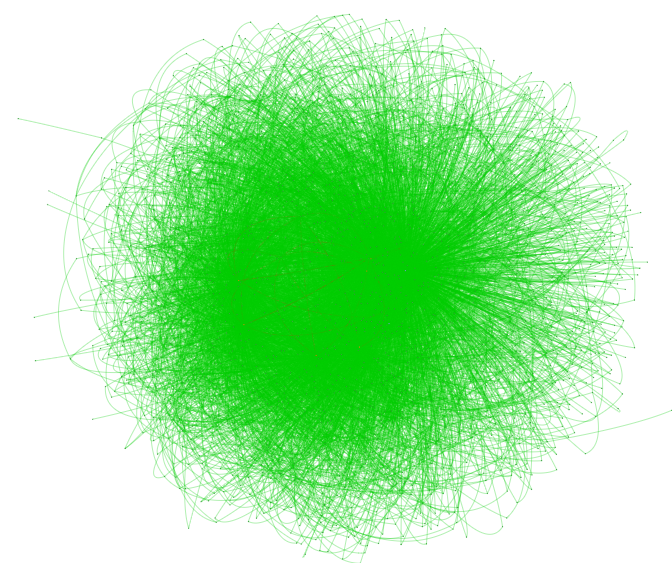

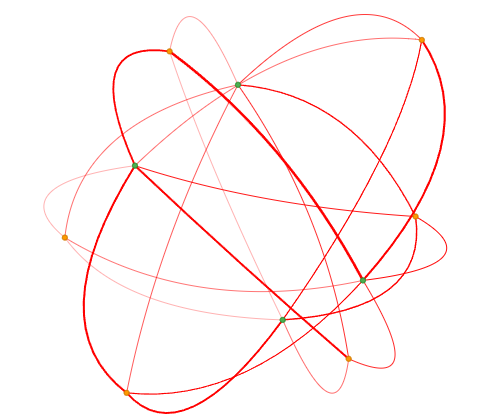

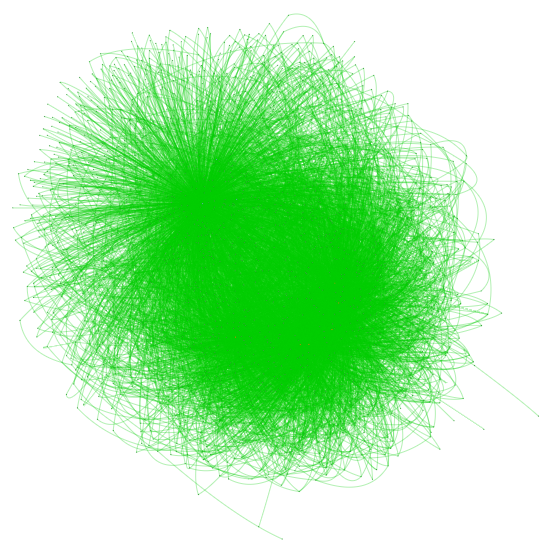

Таким образом, на втором рисунке представлена структура мошеннических транзакций, которая кардинально отличается от легитимной активности (1й и 3й рисунки).

Малое количество узлов (менее 10) и направленность связей указывают на целенаправленную атаку, характерную для кражи мобильного устройства - злоумышленник быстро переводит средства с украденного счета на подконтрольные счета перед обналичиванием.

In [75]:
def plot_graph_plotly(graph, title="Graph Visualization", 
                      fraud_highlight=True, max_nodes=100):
    # Ограничиваем размер графа для производительности
    if graph.number_of_nodes() > max_nodes:
        nodes_list = list(graph.nodes())[:max_nodes]
        subgraph = graph.subgraph(nodes_list)
    else:
        subgraph = graph
    
    # Вычисляем позиции узлов
    pos = nx.spring_layout(subgraph, k=0.5, iterations=50)
    
    # Координаты узлов
    node_x = [pos[node][0] for node in subgraph.nodes()]
    node_y = [pos[node][1] for node in subgraph.nodes()]
    
    # Узлы
    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode='markers',
        marker=dict(size=10, color='#4CAF50'),
        hoverinfo='text',
        text=[node for node in subgraph.nodes()]
    )
    
    # Ребра
    edge_x, edge_y, edge_colors = [], [], []
    for edge in subgraph.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_x.extend([x0, x1, None])
        edge_y.extend([y0, y1, None])
        
        # Цвет ребра
        if fraud_highlight:
            is_fraud = subgraph.edges[edge].get('is_fraud', False)
            edge_colors.append('#ff0000' if is_fraud else '#00cc00')
        else:
            edge_colors.append('#888888')
    
    edge_trace = go.Scatter(
        x=edge_x, y=edge_y,
        line=dict(width=1, color='#888888'),
        hoverinfo='none',
        mode='lines'
    )
    
    # Создание фигуры
    fig = go.Figure(
        data=[edge_trace, node_trace],
        layout=go.Layout(
            title=title,
            showlegend=False,
            hovermode='closest',
            margin=dict(b=0, l=0, r=0, t=40),
            xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            width=800,
            height=600
        )
    )
    
    return fig

In [80]:
fig1 = plot_graph_plotly(G_fraud, title='Мошеннические транзакции (Plotly)', max_nodes=50)
fig2 = plot_graph_plotly(G_normal, title='Нормальные транзакции (Plotly)', max_nodes=50)

fig1.show()
fig2.show()

Опишем.

На первом рисунке представлена визуализация мошеннических транзакций. Можно отметить ранее выделенные паттерны:
* демонстрация плотной связности между ограниченным числом узлов. 
* такая структура характерна для координированной активности мобильного ботнета, где зараженные устройства совершают множественные переводы между собой.

На втором рисунке прдеставлен граф нормальных транзакций. Можно отметить:
* граф показывает звездообразную топологию с центральными узлами-агентами (RET), через которые происходит большинство легитимных операций.

In [100]:
fig_amount = px.histogram(
    df, 
    x='Amount',
    color='FraudType',
    title='Распределение сумм транзакций',
    labels={'Amount': 'Сумма'},
    width=800,
    height=600
)
fig_amount.show()

fig_type = px.bar(
    df.groupby(['Type', 'FraudType']).size().reset_index(name='count'),
    x='Type', 
    y='count', 
    color='FraudType',
    title='Количество транзакций по типам',
    labels={'Type': 'Тип', 'count': 'Количество'},
    barmode='group',
    width=800,
    height=600
)
fig_type.show()

Анализ распределения транзакций по типам:

1. Финансовый профиль атаки:
   Распределение сумм транзакций показывает, что мошен-
   нические операции области малых сумм, что подтверждает 
   стратегию избегания детектирования через контроль пороговых 
   значений.

2. Абсолютная концентрация fraud в одном типе операций:
   Все 717 мошеннических транзакций имеют тип "Wl" (снятие 
   электронных денег), в то время как остальные типы операций 
   (ArRC, Dt, Ind, Merchant) не содержат ни одной мошеннической 
   транзакции.

3. Нормальное поведение системы:
   Легитимная активность равномерно распределена по всем типам 
   операций с преобладанием пополнений (ArRC, Dt) и переводов 
   между пользователями (Ind).

Таким образом, тип транзакции "Wl" является необходимым (но не достаточным) 
признаком для подозрения на мошенничество. В сочетании с другими 
метриками (плотность графа, ролевая структура, сумма) он позволяет 
эффективно выявлять атаки типа "кража телефона" и "мобильный ботнет".

# Анализ метрик

In [94]:
def calculate_graph_metrics(graph, dataframe):
    metrics = {}
    
    in_degree = dict(graph.in_degree())
    out_degree = dict(graph.out_degree())
    
    top_in = sorted(in_degree.items(), key=lambda x: x[1], reverse=True)[:5]
    metrics['top_incoming'] = top_in
    top_out = sorted(out_degree.items(), key=lambda x: x[1], reverse=True)[:5]
    metrics['top_outgoing'] = top_out
    
    if len(dataframe) > 0:
        metrics['avg_amount'] = dataframe['Amount'].mean()
        metrics['max_amount'] = dataframe['Amount'].max()
    else:
        metrics['avg_amount'] = 0
        metrics['max_amount'] = 0
    
    metrics['density'] = nx.density(graph)

    return metrics

In [95]:
print("\n=== МЕТРИКИ ГРАФОВ ===")
print("\n--- Все транзакции ---")
metrics_all = calculate_graph_metrics(G_all, df)
print(f"Плотность: {metrics_all['density']:.6f}")
print(f"Средняя сумма: {metrics_all['avg_amount']:.2f}")
print(f"Топ по входящим: {metrics_all['top_incoming'][:3]}")

print("\n--- Мошеннические транзакции ---")
metrics_fraud = calculate_graph_metrics(G_fraud, df[df['IsFraud']])
print(f"Плотность: {metrics_fraud['density']:.6f}")
print(f"Средняя сумма: {metrics_fraud['avg_amount']:.2f}")
print(f"Топ по исходящим: {metrics_fraud['top_outgoing'][:3]}")

print("\n--- Нормальные транзакции ---")
metrics_normal = calculate_graph_metrics(G_normal, df[~df['IsFraud']])
print(f"Плотность: {metrics_normal['density']:.6f}")
print(f"Средняя сумма: {metrics_normal['avg_amount']:.2f}")
print(f"Топ по входящим: {metrics_normal['top_incoming'][:3]}")


=== МЕТРИКИ ГРАФОВ ===

--- Все транзакции ---
Плотность: 0.001853
Средняя сумма: 55101.37
Топ по входящим: [('operator', 1550), ('PN_Ret4', 197), ('PN_Ret6', 196)]

--- Мошеннические транзакции ---
Плотность: 0.266667
Средняя сумма: 10591.17
Топ по исходящим: [('PN_EU_0_260', 6), ('PN_EU_1_328', 6), ('PN_EU_0_955', 6)]

--- Нормальные транзакции ---
Плотность: 0.001848
Средняя сумма: 55690.94
Топ по входящим: [('operator', 1550), ('PN_Ret4', 194), ('PN_Ret6', 192)]


Основные выводы:
* Плотность графа мошеннических транзакций примерно в 144 раза выше, чем у легитимных. Это свидетельствует о координированной активности ограниченной группы узлов (не случаные операции).
* Мошеннические транзакции имеют значительно меньшую среднюю сумму, что может указывать мелкие, но частые переводов для минимизации рисков.
* В легитимной активности центральную роль играют агенты оператора (RET), тогда как в мошеннических транзакциях высокую исходящую активность демонстрируют обычные пользователи (EU), что соответствует двум знакомым сценариям:
    * кража телефона - скомпрометированный аккаунт жертвы быстро выводит средства
    * мобильный ботнет - группа зараженных устройств координированно переводит средства

In [66]:
print("\n1. Узлы с высокой степенью (подозрительная активность):")
fraud_nodes = list(G_fraud.nodes())
for node in fraud_nodes[:10]:
    degree = G_fraud.degree(node)
    if degree > 3:
        print(f"   {node}: степень = {degree}")

# Паттерн 2: Анализ типов транзакций в мошенничестве
print("\n2. Распределение типов транзакций в мошенничестве:")
if len(df[df['IsFraud']]) > 0:
    type_dist = df[df['IsFraud']]['Type'].value_counts()
    print(type_dist)

# Паттерн 3: Роль агентов (RET) в мошеннических схемах
print("\n3. Участие агентов (RET) в мошеннических транзакциях:")
fraud_df = df[df['IsFraud']]
ret_sender = (fraud_df['SenderType'] == 'RET').sum()
ret_receiver = (fraud_df['ReceiverType'] == 'RET').sum()
print(f"   Агент как отправитель: {ret_sender}")
print(f"   Агент как получатель: {ret_receiver}")


1. Узлы с высокой степенью (подозрительная активность):
   PN_EU_0_260: степень = 6
   PN_Ret2: степень = 4
   PN_EU_1_328: степень = 6
   PN_Ret6: степень = 4
   PN_EU_0_955: степень = 6
   PN_Ret1: степень = 4
   PN_Ret4: степень = 4
   PN_EU_0_1045: степень = 6
   PN_Ret5: степень = 4
   PN_Ret3: степень = 4

2. Распределение типов транзакций в мошенничестве:
Type
Wl    717
Name: count, dtype: int64

3. Участие агентов (RET) в мошеннических транзакциях:
   Агент как отправитель: 0
   Агент как получатель: 717


Основные выводы:

* Все мошеннические транзакции имеют тип Wl (Withdrawal — снятие электронных денег). Это означает, что злоумышленники не совершают переводы между пользователями и не оплачивают товары — их единственная цель: быстро конвертировать украденные деньги в наличные через агентов оператора.
* В мошеннических транзакциях агенты (RET) никогда не выступают отправителями, но являются получателями в 100% случаев. Это подтверждает классическую схему.

# Дополнительно: отдельные мошеннические схемы

In [111]:
def plot_pattern(data, senders, title):
    sub = data[data['SenderID'].isin(senders)]
    if sub.empty: print(f"{title}: нет данных"); return
    G = nx.DiGraph()
    for _, r in sub.iterrows(): G.add_edge(r['SenderID'], r['ReceiverID'], weight=r['Amount'])
    pos = nx.spring_layout(G, seed=42, k=0.5)
    ex, ey = [], []
    for u, v in G.edges():
        x0, y0 = pos[u]; x1, y1 = pos[v]
        ex += [x0, x1, None]; ey += [y0, y1, None]
    nx_, ny_ = [pos[n][0] for n in G.nodes()], [pos[n][1] for n in G.nodes()]
    fig = go.Figure(data=[
        go.Scatter(x=ex, y=ey, mode='lines', line=dict(width=1.5, color='#ff4444'), hoverinfo='skip'),
        go.Scatter(x=nx_, y=ny_, mode='markers+text', marker=dict(size=14, color='#ff9999'),
                  text=list(G.nodes()), textposition="top center", hoverinfo='text')
    ], layout=go.Layout(title=title, showlegend=False, hovermode='closest',
                       margin=dict(b=0,l=0,r=0,t=40), width=700, height=600,
                       xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                       yaxis=dict(showgrid=False, zeroline=False, showticklabels=False)))
    fig.show()
    print(f"{title}: {G.number_of_nodes()} узлов, {G.number_of_edges()} рёбер")

In [ ]:
df_fraud = df[df['IsFraud'] == 1].copy()

sc = df_fraud.groupby('SenderID').size()

# Кража: топ-1 или топ-2 самых активных отправителей
# Ботнет: остальные отправители с активностью >= 2
theft = sc.iloc[:2].index.tolist() if len(sc) >= 2 else sc.index.tolist()
botnet = sc.iloc[2:].index.tolist()
botnet = [s for s in botnet if sc[s] >= 2]  # оставляем только с >=2 транзакциями

plot_pattern(df_fraud, theft, "Кража мобильного телефона")
plot_pattern(df_fraud, botnet, "Мобильный ботнет")

print(f"\nСтатистика:")
print(f"Кража: {len(theft)} отправителей, {df_fraud[df_fraud['SenderID'].isin(theft)].shape[0]} транзакций")
print(f"Ботнет: {len(botnet)} отправителей, {df_fraud[df_fraud['SenderID'].isin(botnet)].shape[0]} транзакций")
print(f"Тип операций: {df_fraud['Type'].unique().tolist()}")
print(f"Получатели (роли): {df_fraud['ReceiverType'].value_counts().to_dict()}")

Кража мобильного телефона: 8 узлов, 12 рёбер


Мобильный ботнет: 8 узлов, 12 рёбер

Статистика:
Кража: 2 отправителей, 337 транзакций
Ботнет: 2 отправителей, 380 транзакций
Тип операций: ['Wl']
Получатели (роли): {'RET': 717}
